# Lab 1. Linear Transformations

In [178]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

%matplotlib inline
print(np.__version__)

2.0.2


## Part 1. 2D transformations

In [179]:
lynx = np.array([
  [209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44], [20.36, 266.67],
  [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42], [-21.30, 259.65], [-50.65, 267.84],
  [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58], [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58],
  [-192.66, 225.73], [-181.30, 145.03], [-168.05, 104.09], [-184.14, 66.67], [-186.98, 31.58], [-183.20, 3.51],
  [-208.76, -4.68], [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32],
  [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56], [-143.43, -287.72], [-161.42, -240.94], [-282.60, -221.05],
  [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66], [345.09, -400.00], [359.29, -378.95],
  [367.81, -342.69], [346.98, -362.57], [363.08, -302.92], [357.40, -243.27], [348.88, -266.67], [336.57, -201.17],
  [290.18, -135.67], [240.00, -118.13], [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33],
  [247.57, -359.06], [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16],
  [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39], [251.36, -1.17],
  [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82], [220.12, 101.75], [234.32, 160.23],
  [240.00, 230.41], [232.43, 316.96],
])

X = lynx.T 
print(X.shape)

(2, 74)


In [180]:
batman = np.array([[0, 0], [1, 0.2], [0.4, 1], [0.5, 0.4], [0, 0.8], [-0.5, 0.4], [-0.4, 1], [-1, 0.2], [0, 0]])
X_BATMAN = batman.T

### Task 1

In [181]:
def plot_transform(original, transformed, A, title=""):
  fig, ax = plt.subplots(figsize=(6, 6))

  ax.fill(original[0], original[1], color="gray", alpha=0.4, edgecolor="black", label="Original")
  ax.fill(transformed[0], transformed[1], color="tab:blue", alpha=0.5, edgecolor="navy", label="Transformed")

  ax.axhline(0, color="black", linewidth=0.8)
  ax.axvline(0, color="black", linewidth=0.8)
  ax.grid(True, linestyle="--", alpha=0.5)
  ax.set_aspect("equal")
  ax.legend(loc="upper right")
  ax.set_title(title)
  plt.show()

  print("Matrix:")
  print(np.round(A, 3))
  print("det =", round(np.linalg.det(A), 3))

In [182]:
def stretch(X, a, b):
  """Розтяг/стиск: у a разів вздовж осі x, у b разів вздовж осі y."""
  X = X.copy()
  A = np.array([[a, 0],
                [0, b]])
  return A @ X, A

def shear(X, a, b):
  """(зсув, скіс) нахиляє фігуру: кожна точка зсувається вздовж однієї осі на величину, пропорційну її координаті по іншій осі"""
  X = X.copy()
  A = np.array([[1, a],
              [b, 1]])
  return A @ X, A

def reflection(X, a, b):
  """Відбиття відносно прямої, що проходить через початок координат вздовж вектора (a, b)"""
  X = X.copy()
  A = 1 / (a**2 + b**2) * np.array([[a**2 - b**2, 2*a*b],
                                    [2*a*b, b**2 - a**2]])
  return A @ X, A

def rotation(X, theta):
  """Поворот навколо початку координат на кут theta (у радіанах) проти годинникової стрілки"""
  X = X.copy()
  A = np.array([[np.cos(theta), -np.sin(theta)],
                [np.sin(theta),  np.cos(theta)]])
  return A @ X, A

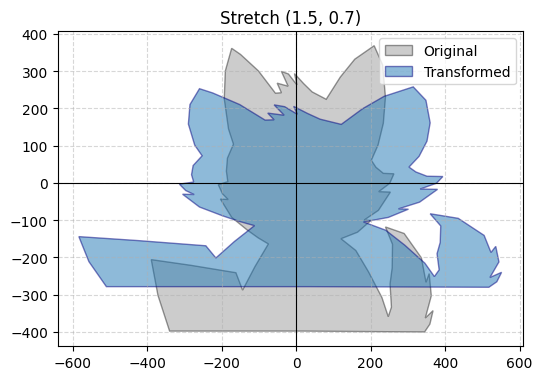

Matrix:
[[1.5 0. ]
 [0.  0.7]]
det = 1.05


In [183]:
Y, A = stretch(X, 1.5, 0.7)
plot_transform(X, Y, A, "Stretch (1.5, 0.7)")

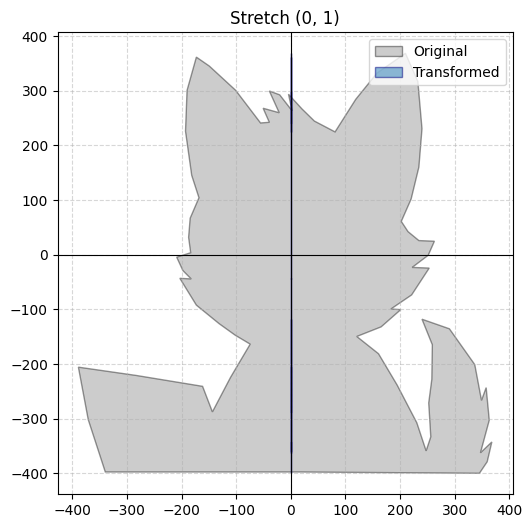

Matrix:
[[0 0]
 [0 1]]
det = 0.0


In [184]:
Y, A = stretch(X, 0, 1)
plot_transform(X, Y, A, "Stretch (0, 1)")

Ранг матриці = 1, усі x зануляються і фігура стає простою лінією.

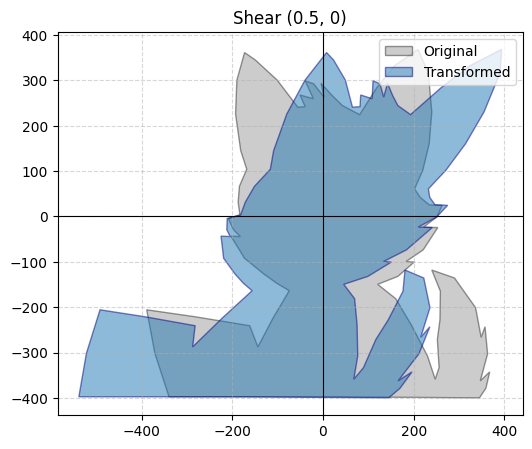

Matrix:
[[1.  0.5]
 [0.  1. ]]
det = 1.0


In [185]:
Y, A = shear(X, 0.5, 0)
plot_transform(X, Y, A, "Shear (0.5, 0)")

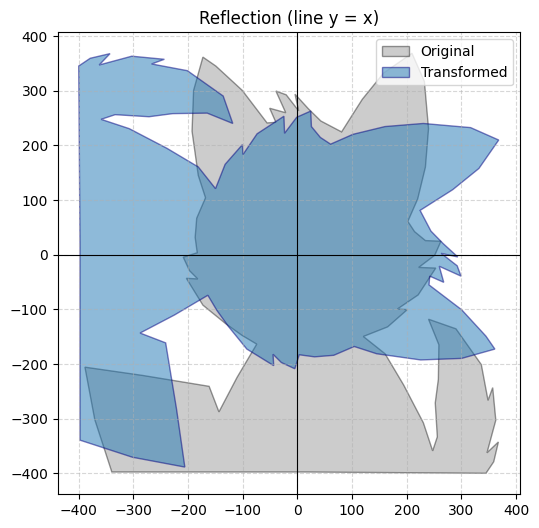

Matrix:
[[0. 1.]
 [1. 0.]]
det = -1.0


In [186]:
Y, A = reflection(X, 1, 1)
plot_transform(X, Y, A, "Reflection (line y = x)")

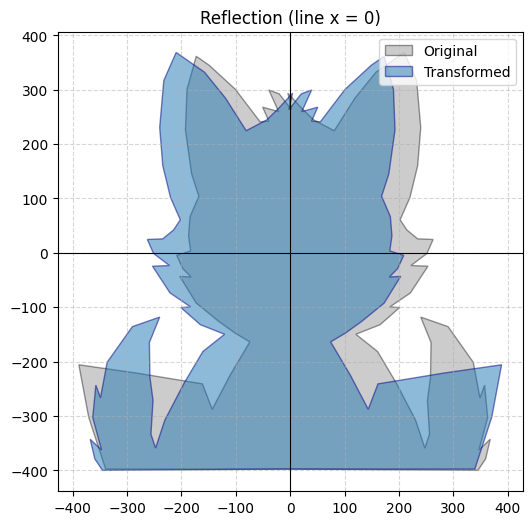

Matrix:
[[-1.  0.]
 [ 0.  1.]]
det = -1.0


In [187]:
Y, A = reflection(X, 0, 1)
plot_transform(X, Y, A, "Reflection (line х = 0)")

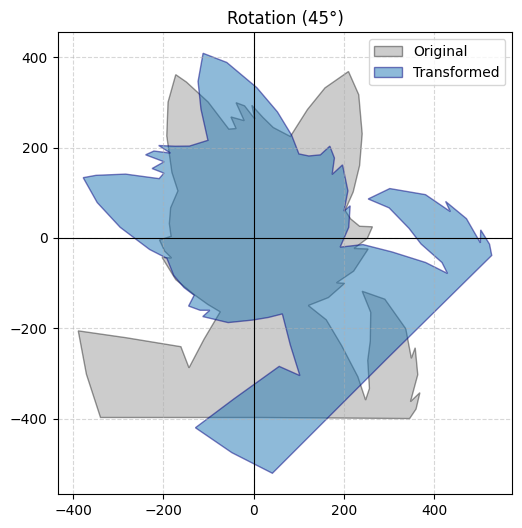

Matrix:
[[ 0.707 -0.707]
 [ 0.707  0.707]]
det = 1.0


In [188]:
Y, A = rotation(X, np.pi / 4)
plot_transform(X, Y, A, "Rotation (45°)")

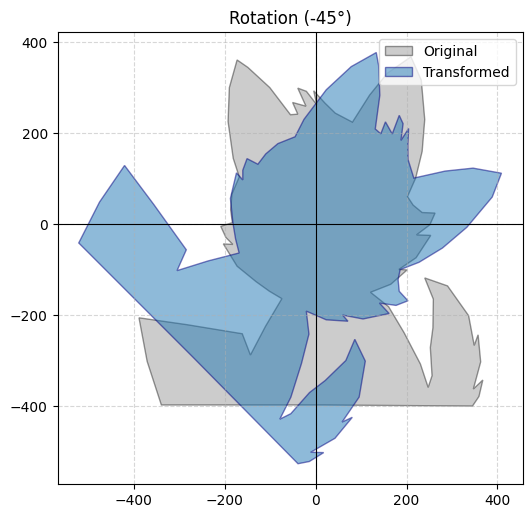

Matrix:
[[ 0.707  0.707]
 [-0.707  0.707]]
det = 1.0


In [189]:
Y, A = rotation(X, -np.pi / 4)
plot_transform(X, Y, A, "Rotation (-45°)") # рух за годинниковою стрілкою

### Task 2

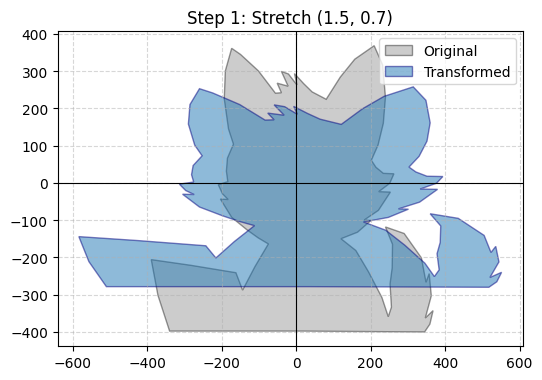

Matrix:
[[1.5 0. ]
 [0.  0.7]]
det = 1.05


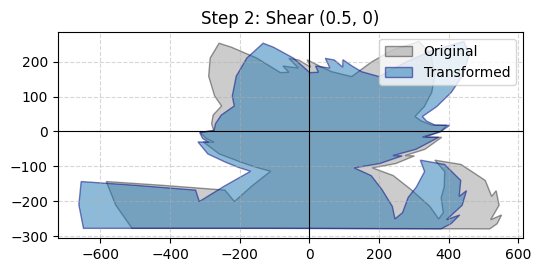

Matrix:
[[1.  0.5]
 [0.  1. ]]
det = 1.0


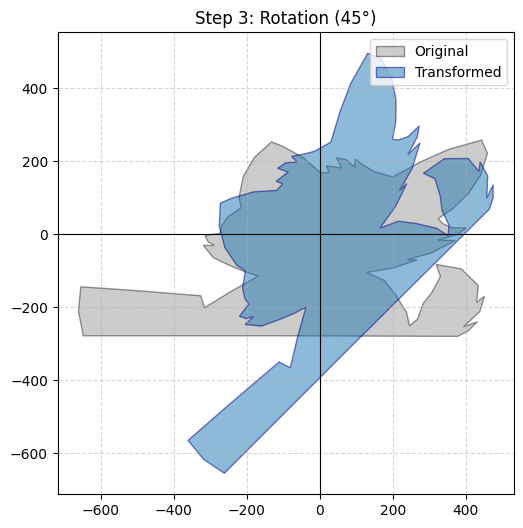

Matrix:
[[ 0.707 -0.707]
 [ 0.707  0.707]]
det = 1.0


In [190]:
Y1, S = stretch(X, 1.5, 0.7)
plot_transform(X, Y1, S, "Step 1: Stretch (1.5, 0.7)")

Y2, H = shear(Y1, 0.5, 0)
plot_transform(Y1, Y2, H, "Step 2: Shear (0.5, 0)")

Y3, R = rotation(Y2, np.pi / 4)
plot_transform(Y2, Y3, R, "Step 3: Rotation (45°)")

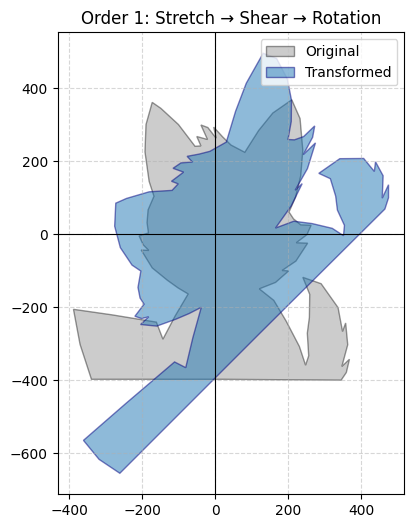

Matrix:
[[ 1.061 -0.247]
 [ 1.061  0.742]]
det = 1.05


In [191]:
M1 = R @ H @ S
plot_transform(X, M1 @ X, M1, "Order 1: Stretch → Shear → Rotation")

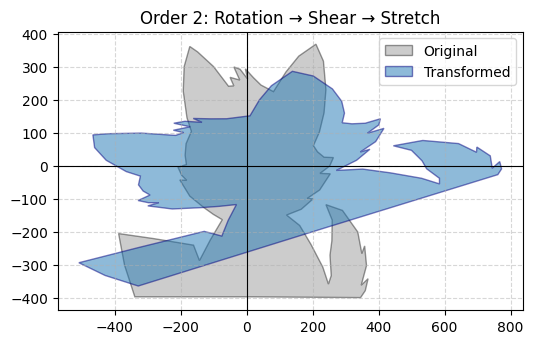

Matrix:
[[ 1.591 -0.53 ]
 [ 0.495  0.495]]
det = 1.05


In [192]:
M2 = S @ H @ R
plot_transform(X, M2 @ X, M2, "Order 2: Rotation → Shear → Stretch")

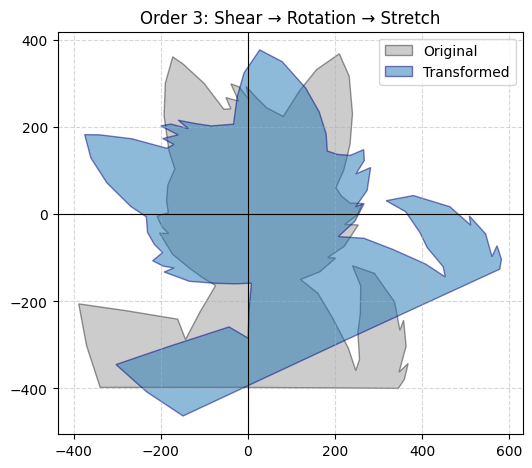

Matrix:
[[ 1.061 -0.53 ]
 [ 0.495  0.742]]
det = 1.05


In [193]:
M3 = S @ R @ H
plot_transform(X, M3 @ X, M3, "Order 3: Shear → Rotation → Stretch")

Як бачимо в трьох випадках отримуємо різне зображення. Порядок застосування лінійних трансформацій впливає.

## Part 2. 3D rotations

### Читання .off файлу та візуалізація

In [194]:
%matplotlib inline
def read_off(filename: str):
  with open(filename, 'r') as f:
    # Перевіряємо, чи перший рядок починається з OFF
    if 'OFF' != f.readline().strip():
      raise ValueError('Not a valid OFF header')

    # Зчитуємо кількість вершин, граней та ребер (третє значення часто ігнорується)
    n_verts, n_faces, _ = map(int, f.readline().strip().split())

    # Зчитуємо координати всіх вершин (x, y, z)
    verts = [list(map(float, f.readline().strip().split())) for _ in range(n_verts)]

    # Зчитуємо грані: перше число у рядку - кількість вершин грані (ігноруємо), далі індекси
    faces = [list(map(int, f.readline().strip().split()[1:])) for _ in range(n_faces)]

  # Повертаємо вершини у вигляді масиву NumPy та список граней
  return np.array(verts), faces

In [195]:
# Функція для візуалізації OFF-моделі у вигляді сітки та точок
# (зручно бачити, як змінюється модель після трансформацій)
def plot_off(vertices, faces):
  fig = plt.figure(figsize=(8, 8))                # створюємо вікно
  ax = fig.add_subplot(111, projection='3d')      # додаємо 3D координатну систему

  # Створюємо полігональну сітку з граней (faces) та додаємо її на графік
  mesh = Poly3DCollection([vertices[face] for face in faces],
                          alpha=0.3, edgecolor='k')  # прозорість 0.3, чорні ребра
  ax.add_collection3d(mesh)

  # Додаємо вершини як червоні точки
  ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=2, c='r')

  # Підписуємо осі
  ax.set_xlabel("X")
  ax.set_ylabel("Y")
  ax.set_zlabel("Z")

  # Автоматично масштабуємо сцену під модель
  ax.auto_scale_xyz(vertices[:, 0], vertices[:, 1], vertices[:, 2])

  plt.show()  # показуємо результат

(11634, 3)
[[0, 1, 2], [1, 6, 7], [6, 1, 0]]


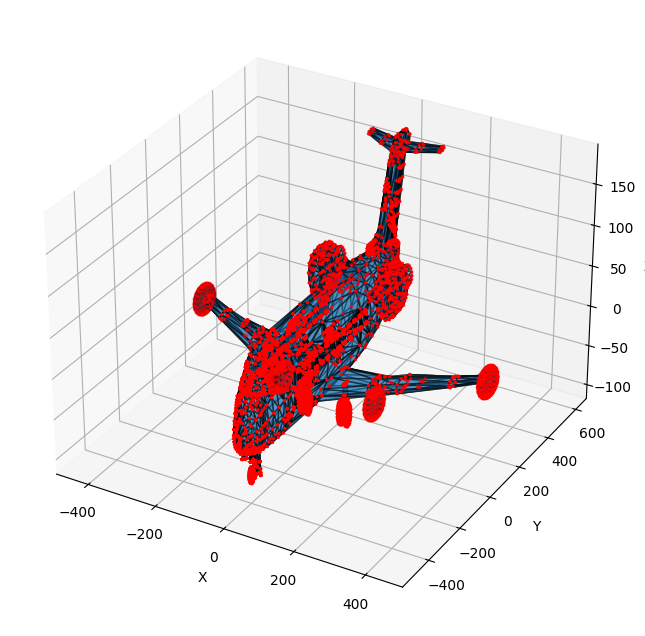

In [196]:
vertices, faces = read_off("data/airplane/test/airplane_0627.off")
print(vertices.shape)
print(faces[:3])

# Центруємо модель, щоб повороти відбувалися навколо її центру
vertices = vertices - vertices.mean(axis=0)

plot_off(vertices, faces)

### Task 3

In [197]:
def rotate_xy(X, theta):
  """Поворот у площині xy (навколо осі z) на кут theta"""
  X = X.copy()
  A = np.array([[np.cos(theta), -np.sin(theta), 0],
                [np.sin(theta),  np.cos(theta), 0],
                [0,              0,             1]])
  return A @ X, A

def rotate_yz(X, theta):
  """Поворот у площині yz (навколо осі x) на кут theta"""
  X = X.copy()
  A = np.array([[1, 0,              0            ],
                [0, np.cos(theta), -np.sin(theta)],
                [0, np.sin(theta),  np.cos(theta)]])
  return A @ X, A

def rotate_xz(X, theta):
  """Поворот у площині xz (навколо осі y) на кут theta"""
  X = X.copy()
  A = np.array([[np.cos(theta), 0, -np.sin(theta)],
                [0,             1,  0            ],
                [np.sin(theta), 0,  np.cos(theta)]])
  return A @ X, A

In [198]:
def plot_rotation_3d(original, rotated, faces, A, title=""):
  """Малює модель до і після повороту поруч (однаковий масштаб і ракурс) та виводить матрицю."""
  fig = plt.figure(figsize=(12, 6))
  lim = np.abs(np.hstack([original, rotated])).max()
  for k, (P, name, color) in enumerate([(original, "Original", "lightgray"),
                                        (rotated, title, "tab:blue")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    V = P.T                                             
    mesh = Poly3DCollection([V[face] for face in faces],
                            facecolor=color, edgecolor="k", linewidth=0.05, alpha=0.5)
    ax.add_collection3d(mesh)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    ax.view_init(elev=20, azim=-60)
    ax.set_title(name)
  plt.tight_layout()
  plt.show()

  print("Matrix:")
  print(np.round(A, 3))
  print("det =", round(np.linalg.det(A), 3))

In [199]:
V = vertices.T
print(V.shape)

(3, 11634)


#### Поворот у площині xy (навколо осі z)

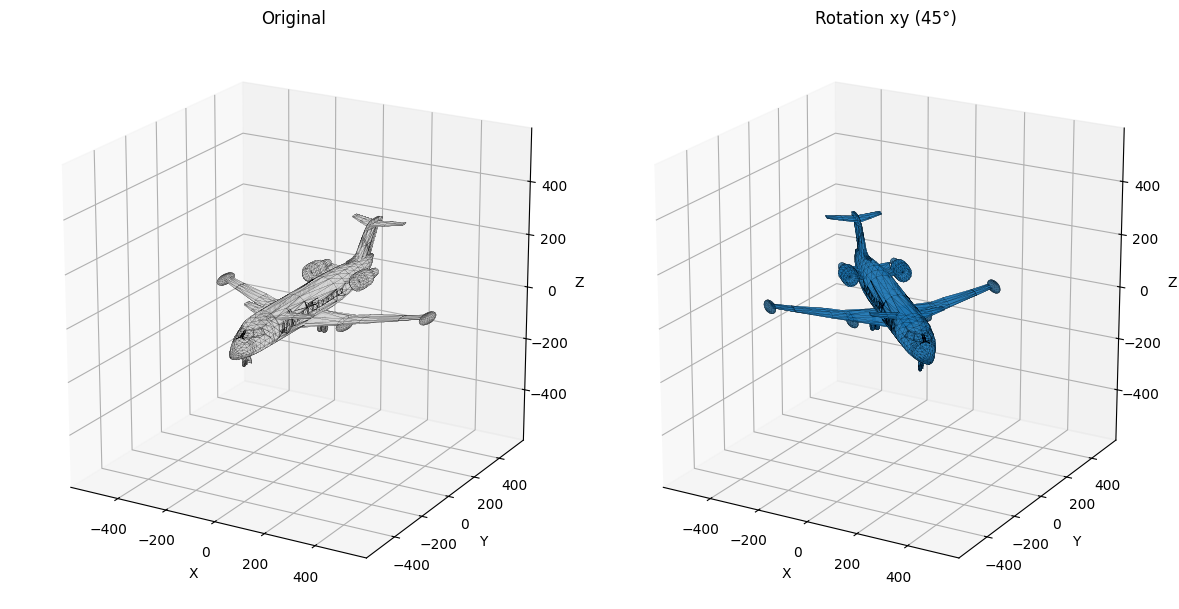

Matrix:
[[ 0.707 -0.707  0.   ]
 [ 0.707  0.707  0.   ]
 [ 0.     0.     1.   ]]
det = 1.0


In [200]:
Y, A = rotate_xy(V, np.pi / 4)
plot_rotation_3d(V, Y, faces, A, "Rotation xy (45°)")

#### Поворот у площині yz (навколо осі x)

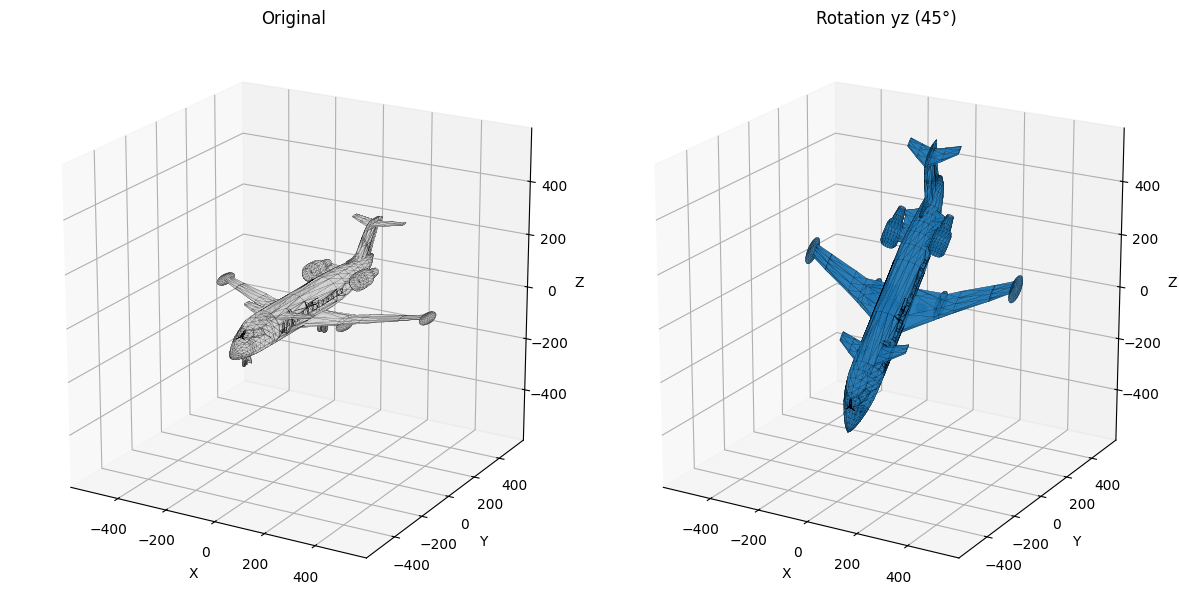

Matrix:
[[ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]
 [ 0.     0.707  0.707]]
det = 1.0


In [201]:
Y, A = rotate_yz(V, np.pi / 4)
plot_rotation_3d(V, Y, faces, A, "Rotation yz (45°)")

#### Поворот у площині xz (навколо осі y)

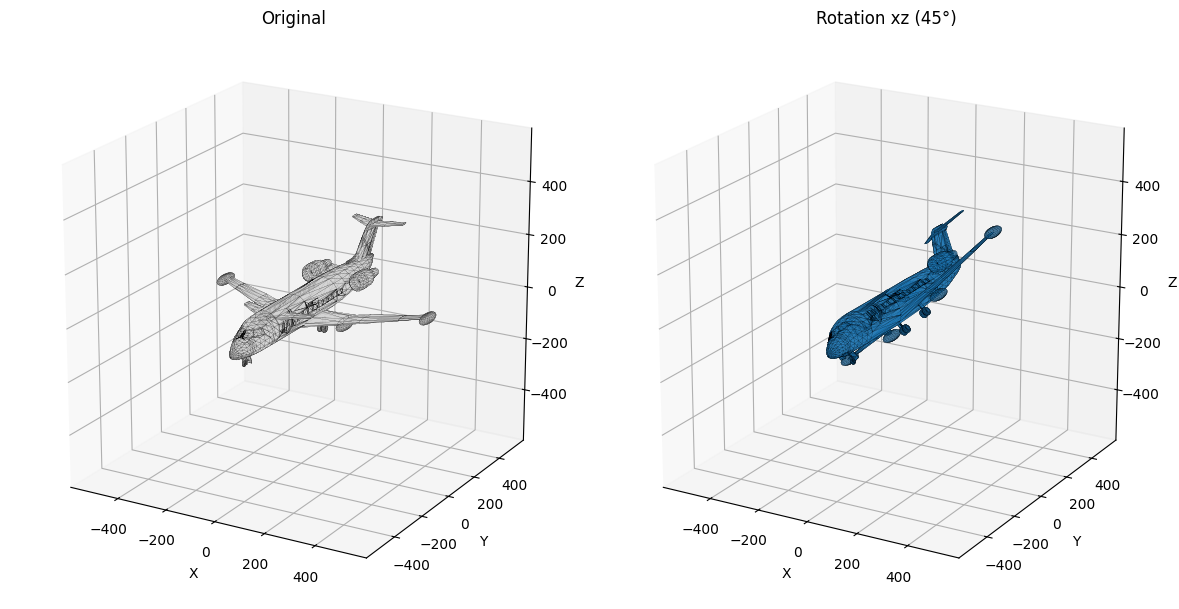

Matrix:
[[ 0.707  0.    -0.707]
 [ 0.     1.     0.   ]
 [ 0.707  0.     0.707]]
det = 1.0


In [202]:
Y, A = rotate_xz(V, np.pi / 4)
plot_rotation_3d(V, Y, faces, A, "Rotation xz (45°)")

### Task 4

Послідовне застосування: True


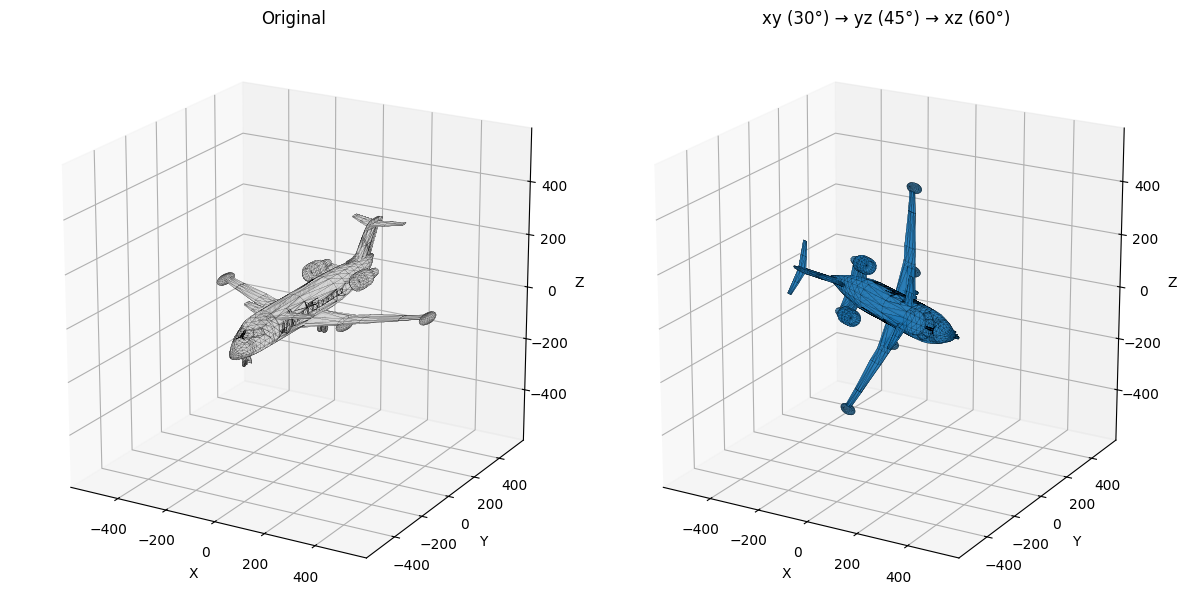

Matrix:
[[ 0.127 -0.78  -0.612]
 [ 0.354  0.612 -0.707]
 [ 0.927 -0.127  0.354]]
det = 1.0


In [203]:
# Композиція: спочатку xy (30°), потім yz (45°), потім xz (60°)
Y1, A_xy = rotate_xy(V, np.pi / 6)
Y2, A_yz = rotate_yz(Y1, np.pi / 4)
Y3, A_xz = rotate_xz(Y2, np.pi / 3)

M = A_xz @ A_yz @ A_xy

print("Послідовне застосування:", np.allclose(M @ V, Y3))
plot_rotation_3d(V, Y3, faces, M, "xy (30°) → yz (45°) → xz (60°)")